In [1]:
from pathlib import Path

import numpy as np

from skimage.io import imread

from matplotlib import pyplot as plt

In [2]:
model_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3")
images_dir = model_dir / "predictions"

In [3]:
labels_dict = {
    1: "granule",
    2: "tail",
    3: "spike"
}

In [4]:
crop_files = []
pred_files = []

for file in zip(images_dir.glob("pred_*"), images_dir.glob("crop_*")):
    pred_files.append(file[0])
    crop_files.append(file[1])    

In [5]:
pred_files

[PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_J5_new_x4300_-10um_0081_1.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_G1_x4300_-10um_0033_1.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_G1_x4300_-10um_0033_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_E4_new_x4300_-10um_0001_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_J5_new_x4300_-10um_0081_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_E4_new_x4300_-10um_0044_0.tif')]

In [6]:
crop_files

[PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_G1_x4300_-10um_0033_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_E4_new_x4300_-10um_0001_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_G1_x4300_-10um_0033_1.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_J5_new_x4300_-10um_0081_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_E4_new_x4300_-10um_0044_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_J5_new_x4300_-10um_0081_1.tif')]

In [16]:
file_pairs = []

for fp in pred_files:
    name = fp.name[5:]
    # print(name)
    for cf in crop_files:
        if cf.name[5:] == name:
            file_pairs.append((cf, fp))
            break

for f in file_pairs:
    print(f[0].name, f[1].name)

crop_40135_J5_new_x4300_-10um_0081_1.tif pred_40135_J5_new_x4300_-10um_0081_1.tif
crop_40135_G1_x4300_-10um_0033_1.tif pred_40135_G1_x4300_-10um_0033_1.tif
crop_40135_G1_x4300_-10um_0033_0.tif pred_40135_G1_x4300_-10um_0033_0.tif
crop_40135_E4_new_x4300_-10um_0001_0.tif pred_40135_E4_new_x4300_-10um_0001_0.tif
crop_40135_J5_new_x4300_-10um_0081_0.tif pred_40135_J5_new_x4300_-10um_0081_0.tif
crop_40135_E4_new_x4300_-10um_0044_0.tif pred_40135_E4_new_x4300_-10um_0044_0.tif


In [223]:
ind = -1 # skip 1 as it does not have any tails
pred_file = file_pairs[ind][1]
crop_file = file_pairs[ind][0]

pred_file, crop_file

(PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/pred_40135_E4_new_x4300_-10um_0044_0.tif'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3/predictions/crop_40135_E4_new_x4300_-10um_0044_0.tif'))

In [224]:
img_pred = imread(pred_file)
img = imread(crop_file)

In [225]:
img_id = crop_file.name.split("_")[-2]
img_id

'0044'

In [226]:
np.unique(img_pred)

array([  0,  85, 170, 255], dtype=uint8)

In [227]:
classes = ["Granules", "Tails", "Spikes"]

Text(0.5, 0.98, '0044')

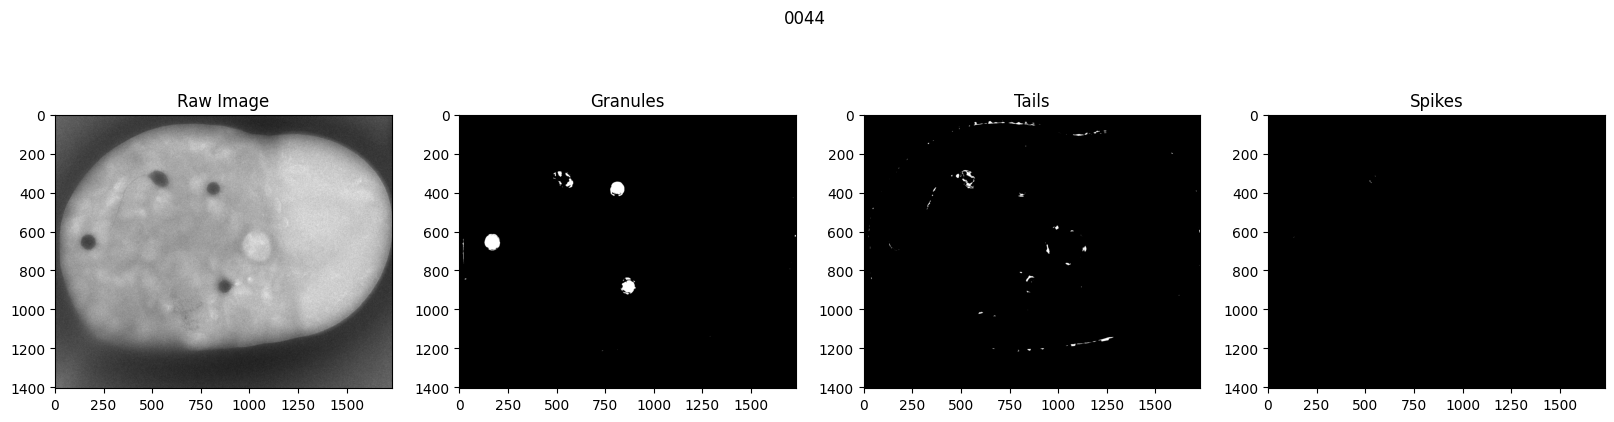

In [228]:
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Raw Image")
for i,val in enumerate(sorted(np.unique(img_pred))[1:]):
    if val == 0:
        continue

    ax[i+1].imshow(img_pred == val, cmap="gray")
    ax[i+1].set_title(classes[i])

plt.suptitle(img_id)
# plt.tight_layout()

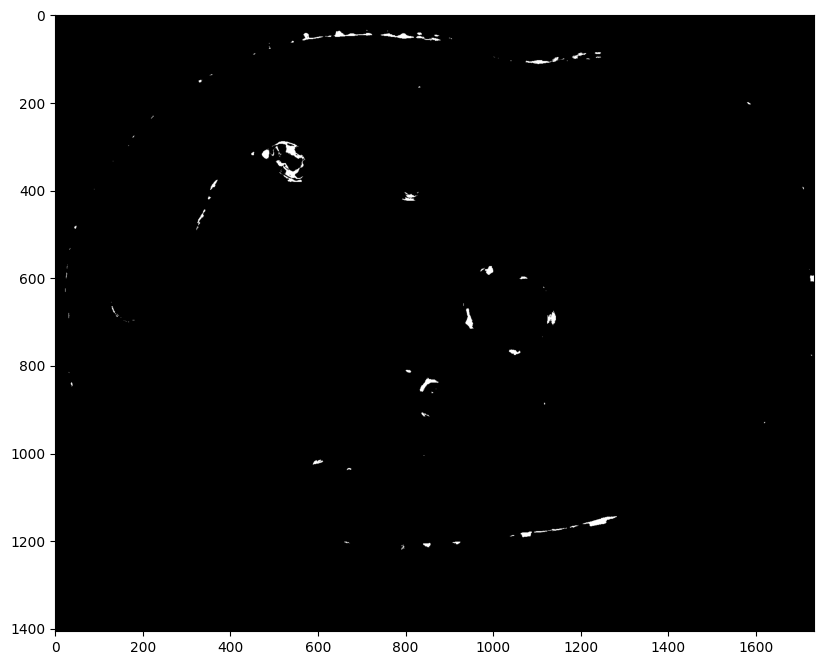

In [235]:
plt.figure(figsize=(10,8))
plt.imshow(img_pred == 170, cmap="gray")

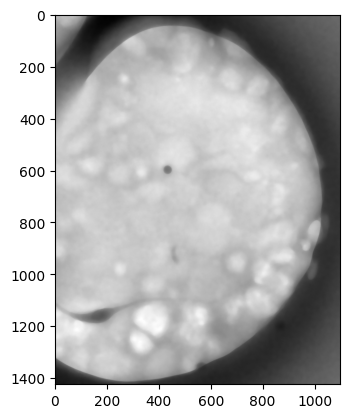

In [207]:
plt.imshow(median(img, disk(9)), cmap="gray")

In [208]:
from skimage.measure import label, regionprops, regionprops_table

In [209]:
np.unique(img_pred)

array([  0,  85, 170, 255], dtype=uint8)

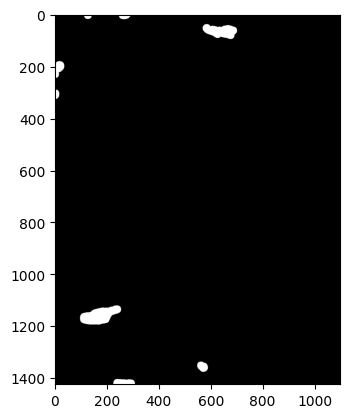

In [210]:
plt.imshow(opening(dilation(img_pred == 170, disk(9)), disk(15)), cmap="gray")

In [174]:
ip = dilation(img_pred == 85, disk(9))
ip = remove_small_objects(ip, min_size=100)
# ip = opening(ip, disk(5))
labels = label(ip)
regions = regionprops(labels)
props = regionprops_table(labels, properties=["label", "area", "bbox", "solidity", "eccentricity", "extent", "major_axis_length", "minor_axis_length"])
props

/tmp/ipykernel_1539944/803950562.py:2: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  ip = remove_small_objects(ip, min_size=100)


{'label': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]),
 'area': array([ 873.,  312.,  704.,  446., 4287.,  472.,  529., 5575.,  788.,
        4403., 5340., 4726., 3751.]),
 'bbox-0': array([ 428,  439,  456,  480,  502,  505,  567,  643,  716,  811, 1002,
        1250, 1398]),
 'bbox-1': array([1457, 1374, 1456, 1488,  403, 1495, 1386,  847,  601,  840, 1521,
         366,  449]),
 'bbox-2': array([ 462,  460,  498,  504,  578,  531,  589,  729,  759,  895, 1087,
        1327, 1468]),
 'bbox-3': array([1498, 1395, 1482, 1513,  477, 1521, 1420,  932,  626,  912, 1606,
         447,  517]),
 'solidity': array([0.88809766, 0.95121951, 0.91073739, 0.96328294, 0.9839339 ,
        0.94969819, 0.93628319, 0.9811686 , 0.92056075, 0.95282406,
        0.977306  , 0.98437825, 0.98451444]),
 'eccentricity': array([0.82328856, 0.24899169, 0.88816571, 0.22793546, 0.40915569,
        0.56016604, 0.82734129, 0.30497734, 0.83859873, 0.62465147,
        0.27391969, 0.31344177, 0.33655886

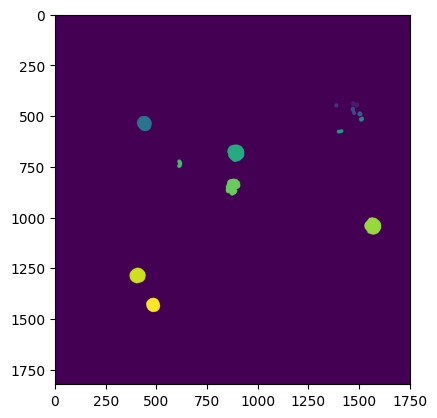

In [175]:
plt.imshow(labels)

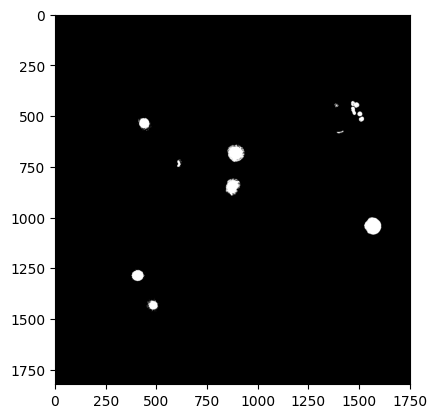

In [178]:
plt.imshow(np.logical_and(ip, ~mask_otsu), cmap="gray")

In [153]:
for axis_major, axis_minor in zip(props["major_axis_length"], props["minor_axis_length"]):
    print(axis_major, axis_minor, axis_major / axis_minor)

77.3159136607805 70.44833873286959 1.09748384492006
86.31439700975427 82.12717114666418 1.0509846595788923
84.21735902757199 66.29356149862853 1.270370110215217
83.99771581130501 80.60073071354182 1.0421458350028638
79.47406210063396 75.5441066086576 1.052021999708525
71.121753344835 67.00779179153595 1.0613952712558825


In [135]:
from skimage.morphology import dilation, opening

/tmp/ipykernel_1539944/3924392597.py:1: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  plt.imshow(remove_small_objects(img_pred == 170, min_size=1000), cmap="gray")


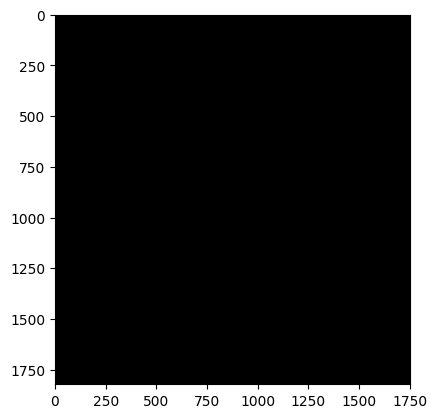

In [136]:
plt.imshow(remove_small_objects(img_pred == 170, min_size=1000), cmap="gray")

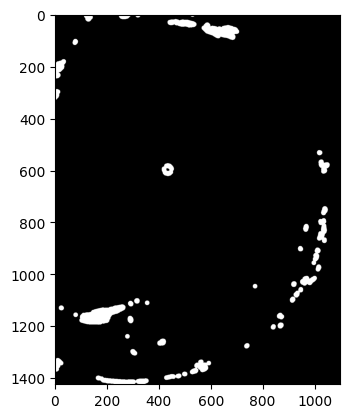

In [119]:
plt.imshow(dilation(img_pred == 170, disk(9)), cmap="gray")

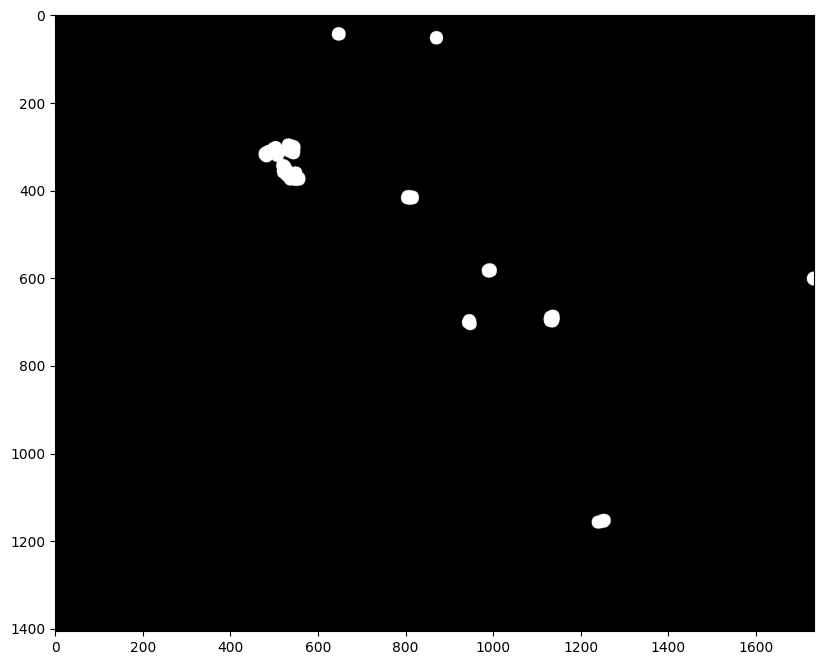

In [236]:
plt.figure(figsize=(10,8))
plt.imshow(opening(dilation(img_pred == 170, disk(9)), disk(15)), cmap="gray")

/tmp/ipykernel_1539944/3622097847.py:1: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  plt.imshow(remove_small_objects(dilation(img_pred == 170, disk(9)), min_size=3500), cmap="gray")


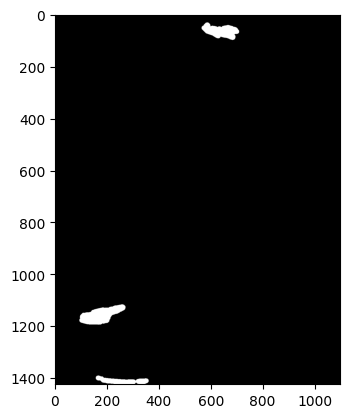

In [214]:
plt.imshow(remove_small_objects(dilation(img_pred == 170, disk(9)), min_size=3500), cmap="gray")

Otsu threshold: 2127


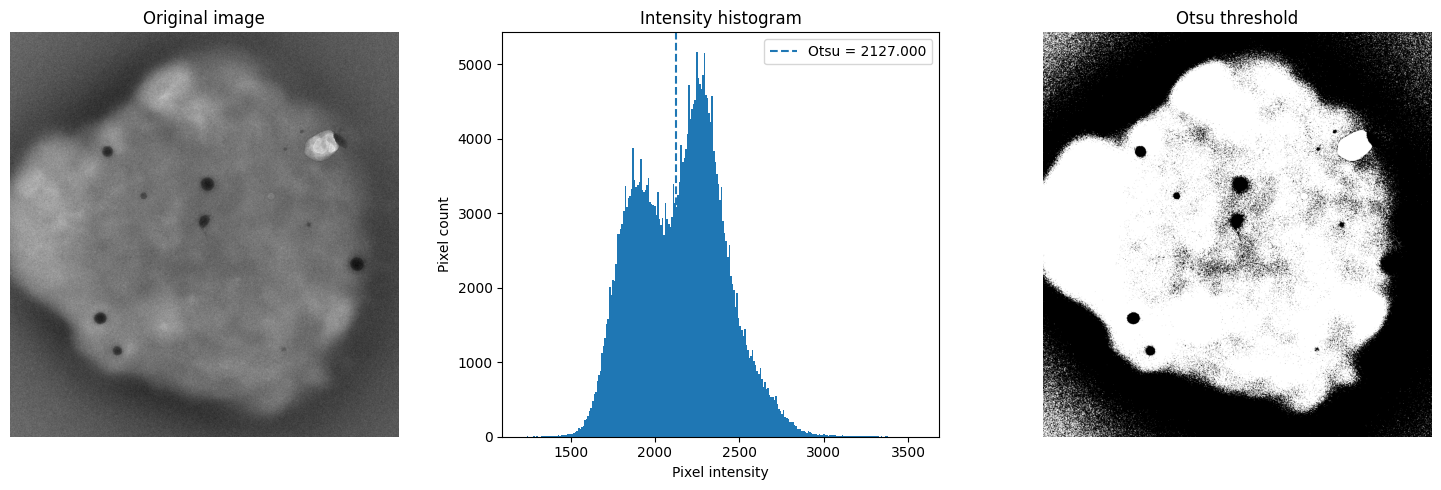

In [177]:
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

# Calculate Otsu threshold
thresh = threshold_otsu(img)

# Create binary mask
mask_otsu = img > thresh

print("Otsu threshold:", thresh)

# Plot image, histogram, and thresholded mask
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original image")
ax[0].axis("off")

ax[1].hist(img.ravel()[::10], bins=256)
ax[1].axvline(thresh, linestyle="--", label=f"Otsu = {thresh:.3f}")
ax[1].set_title("Intensity histogram")
ax[1].set_xlabel("Pixel intensity")
ax[1].set_ylabel("Pixel count")
ax[1].legend()

ax[2].imshow(mask_otsu, cmap="gray")
ax[2].set_title("Otsu threshold")
ax[2].axis("off")

plt.tight_layout()
plt.show()

In [81]:
from scipy.ndimage import binary_fill_holes
from skimage.morphology import binary_closing, remove_small_objects, disk

In [82]:
mask_otsu = binary_fill_holes(mask_otsu)

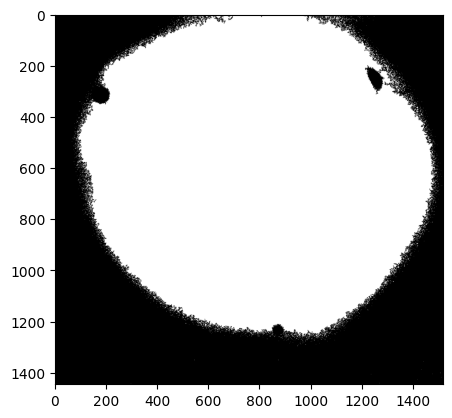

In [83]:
plt.imshow(mask_otsu, cmap="gray")

In [88]:
from skimage.filters import median

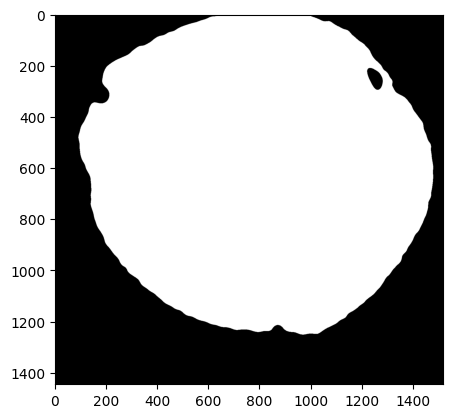

In [111]:
plt.imshow(median(mask_otsu, disk(9)), cmap="gray")

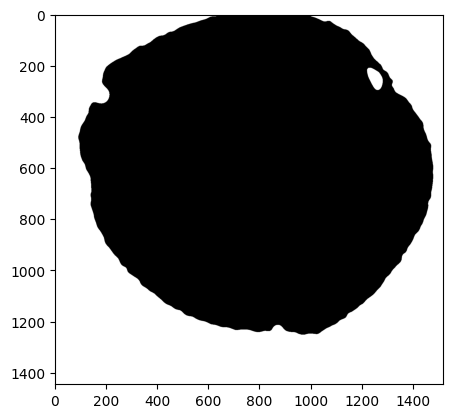

In [112]:
plt.imshow(~mask_otsu, cmap="gray")

In [ ]:
mask_otsu = median(mask_otsu, disk(9))
mask_pred = opening(dilation(img_pred == 170, disk(9)), disk(15))
mask = np.logical_and(~mask_otsu, mask_pred == 170)
# for ind 2, no need to not the otsu mask

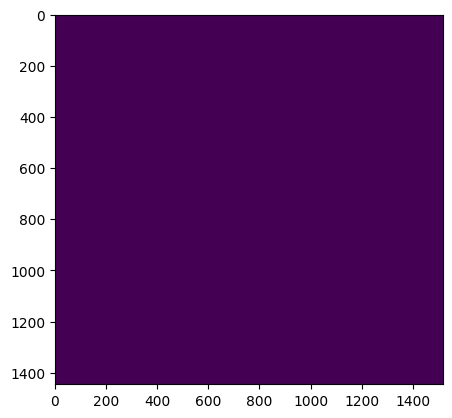

In [110]:
plt.imshow(mask)

True


/tmp/ipykernel_1539944/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


/tmp/ipykernel_1539944/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


...

/tmp/ipykernel_1539944/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


/tmp/ipykernel_1539944/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


False


/tmp/ipykernel_1539944/292543885.py:8: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))


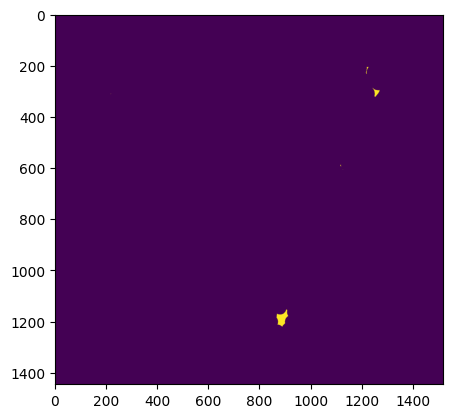

In [93]:
mask_ = mask.copy()
for i in range(10):
    mask_i = mask_.copy()
    mask_ = binary_fill_holes(mask_)

    has_holes = np.any(mask_ != mask_i)
    print(has_holes)
    mask_ = binary_closing(mask_, footprint=disk(2*(3+i)))

mask_ = binary_fill_holes(mask_)
plt.imshow(mask_)

/tmp/ipykernel_1539944/1925699991.py:1: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_clean = remove_small_objects(


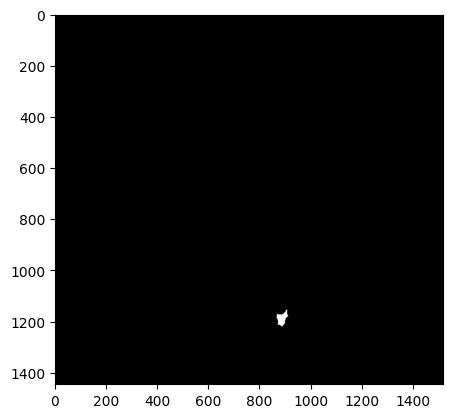

In [94]:
mask_clean = remove_small_objects(
    mask_.astype(bool),
    min_size=1500
)
plt.imshow(mask_clean, cmap="gray")